<a href="https://colab.research.google.com/github/rachanakotiyan/research_paper/blob/main/Copy_of_nfsh5_for_rural_education_3095a8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Interpretable and Leakage-Aware Machine Learning for District-Level Vulnerability Prediction Using NFHS Indicators

## Project Overview
This project develops a district-level machine learning framework to identify socially vulnerable districts using NFHS-based indicators related to women’s education, maternal and adolescent health, child nutrition, and household living conditions. The aim is to build an interpretable decision-support model that can help governments, NGOs, and development planners prioritize districts for intervention when resources are limited.

A key contribution of this work is its leakage-aware evaluation design. Because districts within the same state often share broader policy, cultural, and socio-economic conditions, standard random cross-validation may overestimate predictive performance by allowing geographically related districts to appear in both training and validation sets. To address this, the study uses **GroupKFold cross-validation grouped by state**, which provides a more realistic test of how well models generalize to unseen administrative regions.

The project compares Logistic Regression, Random Forest, and LightGBM, includes a dummy-classifier baseline, evaluates both random and grouped validation strategies, and emphasizes ROC-AUC and PR-AUC as primary performance metrics. In addition, the workflow examines threshold sensitivity, overfitting, and interpretability to produce robust and policy-relevant findings.

##           Project Workflow

```mermaid
flowchart TD
    A[District-Level NFHS Data] --> B[Preprocessing and Target Definition]
    B --> C[Feature Construction]
    C --> D[Modeling: LR, RF, LightGBM, Dummy]
    D --> E[Validation: Random K-Fold vs State-Wise GroupKFold]
    E --> F[Model Comparison and Hyperparameter Tuning]
    F --> G[Robustness and Interpretability Analysis]
    G --> H[Final Model Selection and Conclusions]
```

## Project Workflow

```mermaid
flowchart TD
    A["District-Level NFHS-5 Data (704 districts)"] --> B["Preprocessing and Target Definition (35% threshold)"]
    B --> C["Predictor Selection (25 of 103 indicators)"]
    C --> D["Modeling: LR, RF, LightGBM, Dummy"]
    D --> E["Validation: Random K-Fold vs State-Wise GroupKFold"]
    E --> F["Model Comparison (mean ± SD, 95% CI, paired differences)"]
    F --> G["Robustness and Interpretability Analysis (threshold, predictor selection, LR coefficients)"]
```

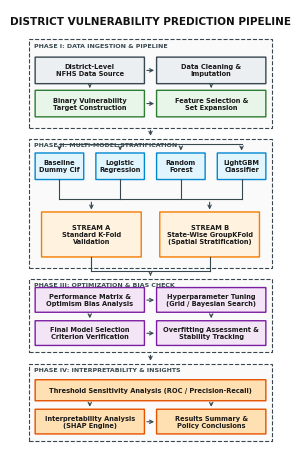

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 1. Dimensions setup (Slightly wider 8.2 cm width, fixed 12 cm height layout)
width_cm = 8.2
height_cm = 12
figsize_inches = (width_cm / 2.54, height_cm / 2.54)

fig, ax = plt.subplots(figsize=figsize_inches)
ax.set_xlim(0, 8.2)
ax.set_ylim(0, 12)
ax.axis("off")

# Document Title (Clean, Professional Typography)
ax.text(
    4.1,
    11.6,
    "DISTRICT VULNERABILITY PREDICTION PIPELINE",
    fontsize=7.5,
    fontweight="black",
    ha="center",
    color="#111111",
)

# Helper function for drawing component boxes
def draw_component(ax, x, y, w, h, text, bg_color="#ffffff", edge_color="#b0bec5", text_color="#1a1a1a", lw=1.0, ls="-"):
    rect = patches.FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.01",
        facecolor=bg_color,
        edgecolor=edge_color,
        linewidth=lw,
        linestyle=ls
    )
    ax.add_patch(rect)
    if text:
        ax.text(
            x + w / 2,
            y + h / 2,
            text,
            fontsize=4.8,
            fontweight="bold",
            ha="center",
            va="center",
            color=text_color,
            wrap=True,
            linespacing=1.2,
        )

# Helper function for container blocks (Subgraphs)
def draw_container(ax, x, y, w, h, title, border_color="#37474f"):
    rect = patches.Rectangle(
        (x, y), w, h, linewidth=0.8, edgecolor=border_color, facecolor="#fafafa", linestyle="--"
    )
    ax.add_patch(rect)
    ax.text(
        x + 0.15,
        y + h - 0.22,
        title,
        fontsize=4.5,
        fontweight="black",
        color=border_color,
        ha="left",
    )


# =========================================================================
# PHASE I: DATA ACQUISITION & FEATURE ENGINEERING
# =========================================================================
draw_container(ax, 0.3, 8.8, 7.6, 2.4, "PHASE I: DATA INGESTION & PIPELINE")

draw_component(ax, 0.5, 10.0, 3.4, 0.7, "District-Level\nNFHS Data Source", "#eceff1", "#37474f")
draw_component(ax, 4.3, 10.0, 3.4, 0.7, "Data Cleaning &\nImputation", "#eceff1", "#37474f")
draw_component(ax, 0.5, 9.1, 3.4, 0.7, "Binary Vulnerability\nTarget Construction", "#e8f5e9", "#2e7d32")
draw_component(ax, 4.3, 9.1, 3.4, 0.7, "Feature Selection &\nSet Expansion", "#e8f5e9", "#2e7d32")


# =========================================================================
# PHASE II: PARALLEL MODELING & STRATIFICATION
# =========================================================================
draw_container(ax, 0.3, 5.0, 7.6, 3.5, "PHASE II: MULTI-MODEL STRATIFICATION")

# Parallel Model Bench
draw_component(ax, 0.5, 7.4, 1.5, 0.7, "Baseline\nDummy Clf", "#e1f5fe", "#0288d1")
draw_component(ax, 2.4, 7.4, 1.5, 0.7, "Logistic\nRegression", "#e1f5fe", "#0288d1")
draw_component(ax, 4.3, 7.4, 1.5, 0.7, "Random\nForest", "#e1f5fe", "#0288d1")
draw_component(ax, 6.2, 7.4, 1.5, 0.7, "LightGBM\nClassifier", "#e1f5fe", "#0288d1")

# Dual Cross-Validation Streams
draw_component(ax, 0.7, 5.3, 3.1, 1.2, "STREAM A\nStandard K-Fold\nValidation", "#fff3e0", "#f57c00")
draw_component(ax, 4.4, 5.3, 3.1, 1.2, "STREAM B\nState-Wise GroupKFold\n(Spatial Stratification)", "#fff3e0", "#f57c00")


# =========================================================================
# PHASE III: RIGOROUS EVALUATION & TUNING
# =========================================================================
draw_container(ax, 0.3, 2.7, 7.6, 2.0, "PHASE III: OPTIMIZATION & BIAS CHECK")

draw_component(ax, 0.5, 3.8, 3.4, 0.65, "Performance Matrix &\nOptimism Bias Analysis", "#f3e5f5", "#7b1fa2")
draw_component(ax, 4.3, 3.8, 3.4, 0.65, "Hyperparameter Tuning\n(Grid / Bayesian Search)", "#f3e5f5", "#7b1fa2")
draw_component(ax, 0.5, 2.9, 3.4, 0.65, "Final Model Selection\nCriterion Verification", "#f3e5f5", "#7b1fa2")
draw_component(ax, 4.3, 2.9, 3.4, 0.65, "Overfitting Assessment &\nStability Tracking", "#f3e5f5", "#7b1fa2")


# =========================================================================
# PHASE IV: POST-HOC ANALYSIS & INTERPRETABILITY
# =========================================================================
draw_container(ax, 0.3, 0.3, 7.6, 2.1, "PHASE IV: INTERPRETABILITY & INSIGHTS")

draw_component(ax, 0.5, 1.4, 7.2, 0.55, "Threshold Sensitivity Analysis (ROC / Precision-Recall)", "#ffe0b2", "#e65100")
draw_component(ax, 0.5, 0.5, 3.4, 0.65, "Interpretability Analysis\n(SHAP Engine)", "#ffe0b2", "#e65100")
draw_component(ax, 4.3, 0.5, 3.4, 0.65, "Results Summary &\nPolicy Conclusions", "#ffe0b2", "#e65100")


# =========================================================================
# CONNECTOR LINES AND ARROWS (Aligned to new Width positions)
# =========================================================================
arrow_props = dict(arrowstyle="->", lw=0.8, color="#37474f", mutation_scale=6)

# Phase 1 internal paths
ax.annotate("", xy=(4.3, 10.35), xytext=(3.9, 10.35), arrowprops=arrow_props)
ax.annotate("", xy=(2.2, 9.8), xytext=(2.2, 10.0), arrowprops=arrow_props)
ax.annotate("", xy=(6.0, 9.8), xytext=(6.0, 10.0), arrowprops=arrow_props)
ax.annotate("", xy=(4.3, 9.45), xytext=(3.9, 9.45), arrowprops=arrow_props)

# Inter-Phase 1 to Phase 2 Main Trunk
ax.annotate("", xy=(4.1, 8.5), xytext=(4.1, 8.8), arrowprops=arrow_props)

# Parallel split to 4 models
ax.plot([1.25, 6.95], [8.35, 8.35], color="#37474f", lw=0.8)
for x_pos in [1.25, 3.15, 5.05, 6.95]:
    ax.annotate("", xy=(x_pos, 8.1), xytext=(x_pos, 8.35), arrowprops=arrow_props)

# 4 Models routing down into validation streams
for x_pos in [1.25, 3.15, 5.05, 6.95]:
    ax.plot([x_pos, x_pos], [7.4, 6.85], color="#37474f", lw=0.8)
ax.plot([1.25, 6.95], [6.85, 6.85], color="#37474f", lw=0.8)
ax.annotate("", xy=(2.25, 6.5), xytext=(2.25, 6.85), arrowprops=arrow_props)
ax.annotate("", xy=(5.95, 6.5), xytext=(5.95, 6.85), arrowprops=arrow_props)

# Validation streams merging into Phase 3
ax.plot([2.25, 2.25], [5.3, 4.9], color="#37474f", lw=0.8)
ax.plot([5.95, 5.95], [5.3, 4.9], color="#37474f", lw=0.8)
ax.plot([2.25, 5.95], [4.9, 4.9], color="#37474f", lw=0.8)
ax.annotate("", xy=(4.1, 4.7), xytext=(4.1, 4.9), arrowprops=arrow_props)

# Phase 3 matrix internal sequencing paths
ax.annotate("", xy=(4.3, 4.12), xytext=(3.9, 4.12), arrowprops=arrow_props)
ax.annotate("", xy=(2.2, 3.55), xytext=(2.2, 3.8), arrowprops=arrow_props)
ax.annotate("", xy=(6.0, 3.55), xytext=(6.0, 3.8), arrowprops=arrow_props)
ax.annotate("", xy=(4.3, 3.22), xytext=(3.9, 3.22), arrowprops=arrow_props)

# Inter-Phase 3 to Phase 4 Main Trunk
ax.annotate("", xy=(4.1, 2.4), xytext=(4.1, 2.7), arrowprops=arrow_props)

# Phase 4 sequence paths
ax.annotate("", xy=(2.2, 1.15), xytext=(2.2, 1.4), arrowprops=arrow_props)
ax.annotate("", xy=(6.0, 1.15), xytext=(6.0, 1.4), arrowprops=arrow_props)
ax.annotate("", xy=(4.3, 0.82), xytext=(3.9, 0.82), arrowprops=arrow_props)

# Final formatting save adjustments
plt.tight_layout()
plt.savefig("fixed_spacious_grid.png", dpi=400, bbox_inches="tight")
plt.show()


In [ ]:
# Imports and configuration

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    KFold,
    GroupKFold,
    GridSearchCV,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    make_scorer
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from lightgbm import LGBMClassifier

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Plot settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Reproducibility
RANDOM_STATE = 42

print("Imports and configuration loaded successfully.")

Imports and configuration loaded successfully.


In [ ]:
# Load dataset

df = pd.read_csv("/kaggle/input/datasets/saharmariam/ndap-for-rural-areas/NDAP_REPORT_6822.csv")

print("Dataset loaded successfully.")
print(f"Shape: {df.shape}")
display(df.head())

Dataset loaded successfully.
Shape: (704, 110)


,Country,State lgd code,State,District lgd code,District,Year,Women age group 15 to 19 years who are anaemic (%) (UOM:%(Percentage)) |Scaling Factor:1,Women age group 15 to 49 years who are anaemic (%) (UOM:%(Percentage)) |Scaling Factor:1,Married women age group 15 to 49 years use any family planning methods (%) (UOM:%(Percentage)) |Scaling Factor:1,Married women age group 15 to 49 years any modern family planning method (%) (UOM:%(Percentage)) |Scaling Factor:1,Average out of pocket expenditure for each delivery in public health facility (UOM:INR(IndianRupees)) |Scaling Factor:1,Births attended by skilled health personnel (%) (UOM:%(Percentage)) |Scaling Factor:1,Births delivered by caesarean section (%) (UOM:%(Percentage)) |Scaling Factor:1,Births in private health facility delivered by caesarean section (%) (UOM:%(Percentage)) |Scaling Factor:1,Births in public health facility delivered by caesarean section (%) (UOM:%(Percentage)) |Scaling Factor:1,Births in the 5 years preceding the survey that are third or higher order (%) (UOM:%(Percentage)) |Scaling Factor:1,Breastfeeding children age group 6 to 23 months receiving an adequate diet (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 12 to 23 months fully vaccinated based on information from either vaccination card or mothers recall (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 12 to 23 months fully vaccinated based on information from vaccination card only (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 12 to 23 months who have received 3 doses of Penta or diphtheria tetanus toxoids and pertussis (DTP) vaccine (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 12 to 23 months who have received 3 doses of Penta or Hepatitis B vaccine (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 12 to 23 months who have received 3 doses of Polio vaccine (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 12 to 23 months who have received 3 doses of Rotavirus vaccine (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 12 to 23 months who have received Bacillus Calmette Guerin (BCG) (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 12 to 23 months who have received the first dose of measles containing vaccine (MCV) (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 12 to 23 months who received most of their vaccinations in a private health facility (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 12 to 23 months who received most of their vaccinations in a public health facility (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 24 to 35 months who have received a second dose of measles containing vaccine (MCV) (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age 5 years who attended pre-primary school during the year 2019-20 (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 6 to 59 months who are anaemic (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 6 to 8 months receiving solid or semisolid food and breastmilk (%) (UOM:%(Percentage)) |Scaling Factor:1,Children age group 9 to 35 months who received vitamin A dose in the last 6 months (%) (UOM:%(Percentage)) |Scaling Factor:1,Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%) (UOM:%(Percentage)) |Scaling Factor:1,Children under 5 years who are overweight (weight-for-height) (%) (UOM:%(Percentage)) |Scaling Factor:1,Children under 5 years who are severely wasted (weight-for-height) (%) (UOM:%(Percentage)) |Scaling Factor:1,Children under 5 years who are stunted (height-for-age) (%) (UOM:%(Percentage)) |Scaling Factor:1,Children under 5 years who are underweight (weight-for-age) (%) (UOM:%(Percentage)) |Scaling Factor:1,Children under 5 years who are wasted (weight-for-height) (%) (UOM:%(Percentage)) |Scaling Factor:1,Children under age 3 years breastfed within one hour of birth (%) (UOM:%(Percentage)) |Scaling Factor:1,Children under age 5 y

In [ ]:
# Basic dataset overview

print("Column names:")
display(pd.DataFrame({"column": df.columns}))

print("\nData types:")
display(df.dtypes.reset_index().rename(columns={"index": "column", 0: "dtype"}))

print("\nMissing values per column:")
missing_df = pd.DataFrame({
    "column": df.columns,
    "missing_count": df.isna().sum().values,
    "missing_percent": (df.isna().mean().values * 100)
}).sort_values("missing_percent", ascending=False)

display(missing_df)

print("\nSummary statistics:")
display(df.describe(include="all").T)

Column names:


,column
0,Country
1,State lgd code
2,State
3,District lgd code
4,District
...,...
105,Women suffering from high or very high blood s...
106,Women suffering from very high blood sugar lev...
107,Women suffering from elevated blood pressure (...
108,Women-mildly elevated blood pressure (%) (UOM:...



Data types:


,column,dtype
0,Country,object
1,State lgd code,int64
2,State,object
3,District lgd code,int64
4,District,object
...,...,...
105,Women suffering from high or very high blood s...,float64
106,Women suffering from very high blood sugar lev...,float64
107,Women suffering from elevated blood pressure (...,float64
108,Women-mildly elevated blood pressure (%) (UOM:...,float64



Missing values per column:


,column,missing_count,missing_percent
30,Children age group 6 to 8 months receiving sol...,329,46.7330
78,Non-breastfeeding children age group 6 to 23 m...,328,46.5909
44,Children with diarrhoea in the 2 weeks precedi...,260,36.9318
42,Children with diarrhoea in the 2 weeks precedi...,260,36.9318
43,Children with diarrhoea in the 2 weeks precedi...,260,36.9318
...,...,...,...
105,Women suffering from high or very high blood s...,0,0.0000
106,Women suffering from very high blood sugar lev...,0,0.0000
107,Women suffering from elevated blood pressure (...,0,0.0000
108,Women-mildly elevated blood pressure (%) (UOM:...,0,0.0000



Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Country,704,1,India,704,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State lgd code,704.0000,NaN,NaN,NaN,17.9474,9.9205,1.0000,9.0000,19.0000,24.0000,38.0000
State,704,34,Uttar Pradesh,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District lgd code,704.0000,NaN,NaN,NaN,354.4588,204.7204,1.0000,177.7500,353.5000,531.2500,720.0000
District,704,701,Bilaspur,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
Women suffering from high or very high blood sugar level (%) (UOM:%(Percentage)) |Scaling Factor:1,704.0000,NaN,NaN,NaN,12.4342,4.6108,4.1000,9.0000,11.6500,15.2000,32.1000
Women suffering from very high blood sugar level (%) (UOM:%(Percentage)) |Scaling Factor:1,704.0000,NaN,NaN,NaN,5.5736,2.8080,0.7000,3.6000,4.9000,7.1000,18.0000
Women suffering from elevated blood pressure (%) (UOM:%(Percentage)) |Scaling Factor:1,704.0000,NaN,NaN,NaN,21.3928,5.2310,8.5000,17.6000,21.0000,24.4250,42.1000
Women-mildly elevated blood pressure (%) (UOM:%(Percentage)) |Scaling Factor:1,704.0000,NaN,NaN,NaN,12.6643,3.1313,4.3000,10.5000,12.5000,14.5250,23.7000


## Target Definition

To operationalize district vulnerability as a binary classification task, this study defines the target using the district-level percentage of **women with 10 or more years of schooling**. Districts below a chosen threshold are labeled as **more vulnerable**, while districts at or above the threshold are labeled as **less vulnerable**. This provides a simple and policy-relevant screening target centered on women’s educational attainment.

Because this threshold is an operational definition rather than a universal standard, a later robustness analysis will test nearby threshold values to evaluate sensitivity.

In [ ]:
# Create target variable, grouping variable, and feature pool

target_col = "Women with 10 or more years of schooling (%) (UOM:%(Percentage)) |Scaling Factor:1"
group_col = "State"
district_col = "District"
state_code_col = "State lgd code"
district_code_col = "District lgd code"

THRESHOLD = 35.0  # change if your chosen cutoff is different

df_model = df.copy()

# Binary target: 1 = more vulnerable, 0 = less vulnerable
df_model["vulnerable"] = (df_model[target_col] < THRESHOLD).astype(int)

# Metadata / non-feature columns to exclude
exclude_cols = [
    "Country",
    "State",
    "District",
    "Year",
    "State lgd code",
    "District lgd code",
    target_col,
    "vulnerable"
]

feature_cols = [col for col in df_model.columns if col not in exclude_cols]

X = df_model[feature_cols]
y = df_model["vulnerable"]
groups = df_model[group_col]

print(f"Target column: {target_col}")
print(f"Threshold used: {THRESHOLD}")
print(f"Number of features: {len(feature_cols)}")
print(f"X shape: {X.shape}")
print(f"y distribution:")
display(y.value_counts().rename_axis("class").reset_index(name="count"))

print("\nClass proportions:")
display((y.value_counts(normalize=True) * 100).rename("percent").reset_index())

Target column: Women with 10 or more years of schooling (%) (UOM:%(Percentage)) |Scaling Factor:1
Threshold used: 35.0
Number of features: 103
X shape: (704, 103)
y distribution:


,class,count
0,0,426
1,1,278



Class proportions:


,vulnerable,percent
0,0,60.5114
1,1,39.4886


## Target Definition

This study frames district-level vulnerability as a binary classification problem using the district share of **women with 10 or more years of schooling** as the operational target basis. Districts below a predefined threshold are labeled as **more vulnerable**, while districts at or above the threshold are labeled as **less vulnerable**. This definition provides a simple and policy-relevant screening outcome centered on women’s educational attainment.

Because this threshold is an operational choice rather than a universal ground truth, a later sensitivity analysis will examine whether the main conclusions remain stable under nearby threshold values.

In [ ]:
# Curated feature set

selected_features = [
    "Women age group 15 to 49 years who are anaemic (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Pregnant women age group 15 to 49 years who are anaemic (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Women age group 20 to 24 years married before age 18 years (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Women age group 15 to 19 years who were already mothers or pregnant at the time of the survey (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Women age group 15 to 24 years who use hygienic methods of protection during their menstrual period (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Women age group 15 to 49 years who are literate (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Female population age 6 years and above who ever attended school (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Children age 5 years who attended pre-primary school during the year 2019-20 (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Children under 5 years who are stunted (height-for-age) (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Children under 5 years who are underweight (weight-for-age) (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Children under 5 years who are wasted (weight-for-height) (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Children under 5 years who are severely wasted (weight-for-height) (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Children age group 6 to 59 months who are anaemic (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Children age group 12 to 23 months fully vaccinated based on information from either vaccination card or mothers recall (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Children age group 6 to 23 months receiving an adequate diet (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Mothers who had at least 4 antenatal care visits (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Mothers who had an antenatal check-up in the first trimester (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Institutional births (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Births attended by skilled health personnel (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Households using clean fuel for cooking (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Population living in households that use an improved sanitation facility (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Population living in households with an improved drinking water source (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Population living in households with electricity (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Households using iodized salt (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Population and household profile-households with any usual member covered under a health insurance or financing scheme (%) (UOM:%(Percentage)) |Scaling Factor:1"
]

missing_selected = [col for col in selected_features if col not in df_model.columns]
print("Missing selected columns:", missing_selected)

X = df_model[selected_features].copy()
y = df_model["vulnerable"].copy()
groups = df_model[group_col].copy()

print(f"Selected feature count: {len(selected_features)}")
print(f"Feature matrix shape: {X.shape}")

Missing selected columns: []
Selected feature count: 25
Feature matrix shape: (704, 25)


In [ ]:
# Preprocessing and evaluation setup for the reduced feature set

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        )
    ],
    remainder="drop"
)

scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

cv_random = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_grouped = GroupKFold(n_splits=5)

print("Preprocessing and scoring setup complete.")
print(f"Number of selected numeric features: {len(numeric_features)}")
print("Metrics used:", list(scoring.keys()))
print("Validation strategies: Random K-Fold and State-wise GroupKFold")

Preprocessing and scoring setup complete.
Number of selected numeric features: 25
Metrics used: ['accuracy', 'f1', 'roc_auc', 'pr_auc']
Validation strategies: Random K-Fold and State-wise GroupKFold


## Baseline Classifier

A dummy baseline is used to verify that the proposed machine learning models learn meaningful patterns beyond simple class imbalance. Because the dataset contains more districts in the less vulnerable class than in the vulnerable class, a naive classifier can achieve moderate accuracy by always predicting the majority class. Therefore, a baseline model is evaluated under the same validation settings as the main models to ensure that any observed performance gains are substantive.

In [ ]:
# Dummy baseline under random and grouped validation

def summarize_cv_results(cv_results, model_name, validation_type):
    return {
        "Model": model_name,
        "Validation": validation_type,
        "Accuracy Mean": np.mean(cv_results["test_accuracy"]),
        "Accuracy Std": np.std(cv_results["test_accuracy"]),
        "F1 Mean": np.mean(cv_results["test_f1"]),
        "F1 Std": np.std(cv_results["test_f1"]),
        "ROC-AUC Mean": np.mean(cv_results["test_roc_auc"]),
        "ROC-AUC Std": np.std(cv_results["test_roc_auc"]),
        "PR-AUC Mean": np.mean(cv_results["test_pr_auc"]),
        "PR-AUC Std": np.std(cv_results["test_pr_auc"]),
    }

dummy_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

dummy_random = cross_validate(
    dummy_pipeline,
    X,
    y,
    cv=cv_random,
    scoring=scoring,
    n_jobs=-1
)

dummy_grouped = cross_validate(
    dummy_pipeline,
    X,
    y,
    cv=cv_grouped,
    groups=groups,
    scoring=scoring,
    n_jobs=-1
)

dummy_results = pd.DataFrame([
    summarize_cv_results(dummy_random, "DummyClassifier", "Random K-Fold"),
    summarize_cv_results(dummy_grouped, "DummyClassifier", "State-Wise GroupKFold")
])

display(dummy_results)

,Model,Validation,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std,PR-AUC Mean,PR-AUC Std
0,DummyClassifier,Random K-Fold,0.6051,0.0441,0.0000,0.0000,0.5000,0.0000,0.3949,0.0441
1,DummyClassifier,State-Wise GroupKFold,0.6051,0.0422,0.0000,0.0000,0.5000,0.0000,0.3949,0.0422


## Model Comparison Under Random and Grouped Validation

The main models are evaluated under both standard random cross-validation and state-wise grouped cross-validation. This comparison is central to the study because random splitting may overestimate performance when geographically related districts appear in both training and test folds. In contrast, grouped validation provides a more realistic estimate of how well a model generalizes to previously unseen states or regions.

In [ ]:
# Evaluate main models under random and grouped validation

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

results = []

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Random K-Fold
    cv_results_random = cross_validate(
        pipeline,
        X,
        y,
        cv=cv_random,
        scoring=scoring,
        n_jobs=-1
    )
    results.append(summarize_cv_results(cv_results_random, model_name, "Random K-Fold"))

    # State-wise GroupKFold
    cv_results_grouped = cross_validate(
        pipeline,
        X,
        y,
        cv=cv_grouped,
        groups=groups,
        scoring=scoring,
        n_jobs=-1
    )
    results.append(summarize_cv_results(cv_results_grouped, model_name, "State-Wise GroupKFold"))

results_df = pd.DataFrame(results)

display(results_df.sort_values(["Validation", "PR-AUC Mean"], ascending=[True, False]))

[LightGBM] [Info] Number of positive: 225, number of negative: 338
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001124 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3769
[LightGBM] [Info] Number of data points in the train set: 563, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 

...


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Validation,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std,PR-AUC Mean,PR-AUC Std
0,Logistic Regression,Random K-Fold,0.8935,0.0161,0.8666,0.0259,0.9621,0.0070,0.9463,0.0116
4,LightGBM,Random K-Fold,0.8977,0.0095,0.8701,0.0103,0.9622,0.0108,0.9415,0.0197
2,Random Forest,Random K-Fold,0.8878,0.0136,0.8577,0.0178,0.9569,0.0028,0.9339,0.0074
1,Logistic Regression,State-Wise GroupKFold,0.8409,0.0356,0.8052,0.0420,0.9433,0.0148,0.9175,0.0296
5,LightGBM,State-Wise GroupKFold,0.8239,0.0315,0.7800,0.0406,0.9343,0.0055,0.8969,0.0209
3,Random Forest,State-Wise GroupKFold,0.8125,0.0508,0.7592,0.0714,0.9318,0.0143,0.8912,0.0330


## Performance Comparison Across Validation Strategies

To assess the impact of geographically aware validation, model performance is compared across random cross-validation and state-wise grouped cross-validation. The grouped setting is more realistic because it evaluates whether a model trained on some states can generalize to entirely unseen states. A consistent performance drop from random to grouped validation would indicate that standard random splitting produces optimistic estimates of model quality.

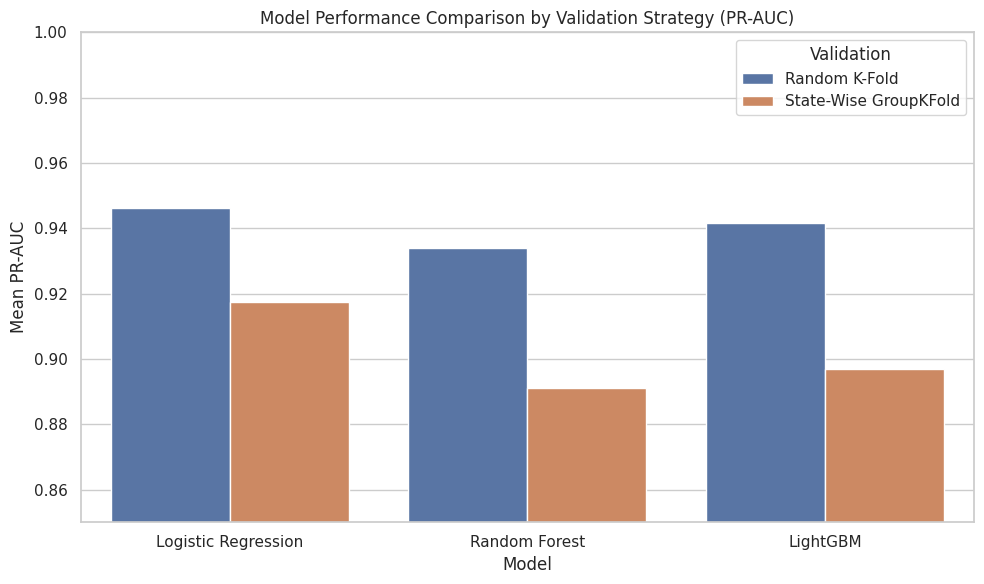

In [ ]:
# Visual comparison of PR-AUC across models and validation strategies

plot_df = results_df.copy()

plt.figure(figsize=(10, 6))
sns.barplot(
    data=plot_df,
    x="Model",
    y="PR-AUC Mean",
    hue="Validation"
)

plt.title("Model Performance Comparison by Validation Strategy (PR-AUC)")
plt.ylabel("Mean PR-AUC")
plt.xlabel("Model")
plt.ylim(0.85, 1.00)
plt.legend(title="Validation")
plt.tight_layout()
plt.show()

In [ ]:
# Collect fold-wise PR-AUC scores for each model and validation strategy

fold_results = []

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Random K-Fold
    scores_random = cross_validate(
        pipeline,
        X,
        y,
        cv=cv_random,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    for i, score in enumerate(scores_random["test_pr_auc"], start=1):
        fold_results.append({
            "Model": model_name,
            "Validation": "Random K-Fold",
            "Fold": i,
            "PR-AUC": score
        })

    # GroupKFold
    scores_grouped = cross_validate(
        pipeline,
        X,
        y,
        cv=cv_grouped,
        groups=groups,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    for i, score in enumerate(scores_grouped["test_pr_auc"], start=1):
        fold_results.append({
            "Model": model_name,
            "Validation": "State-Wise GroupKFold",
            "Fold": i,
            "PR-AUC": score
        })

fold_results_df = pd.DataFrame(fold_results)
display(fold_results_df)


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 

...


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Validation,Fold,PR-AUC
0,Logistic Regression,Random K-Fold,1,0.9427
1,Logistic Regression,Random K-Fold,2,0.9560
2,Logistic Regression,Random K-Fold,3,0.9291
3,Logistic Regression,Random K-Fold,4,0.9418
4,Logistic Regression,Random K-Fold,5,0.9619
5,Logistic Regression,State-Wise GroupKFold,1,0.9178
6,Logistic Regression,State-Wise GroupKFold,2,0.8708
7,Logistic Regression,State-Wise GroupKFold,3,0.9625
8,Logistic Regression,State-Wise GroupKFold,4,0.9086
9,Logistic Regression,State-Wise GroupKFold,5,0.9278


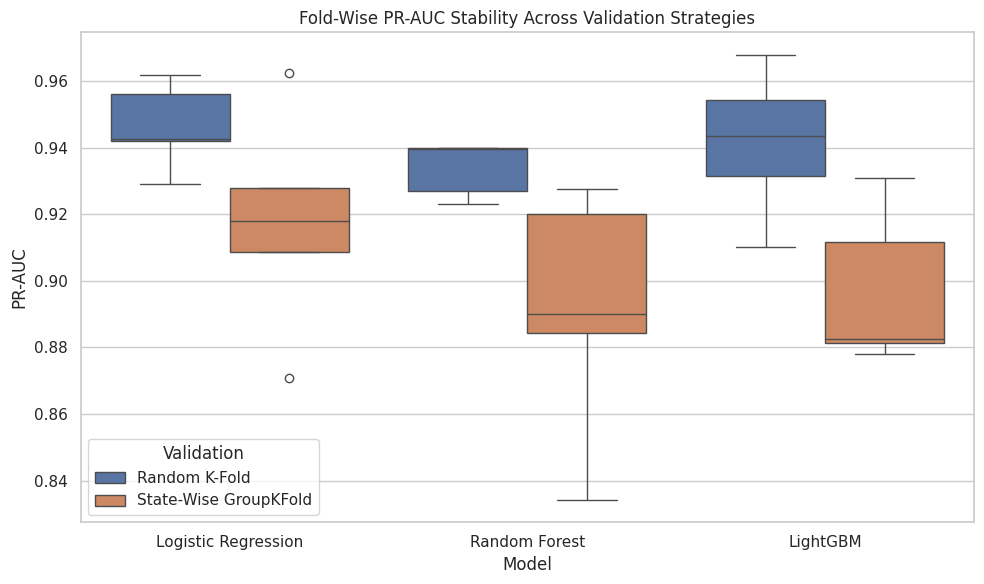

In [ ]:
# Boxplot of fold-wise PR-AUC scores

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=fold_results_df,
    x="Model",
    y="PR-AUC",
    hue="Validation"
)

plt.title("Fold-Wise PR-AUC Stability Across Validation Strategies")
plt.ylabel("PR-AUC")
plt.xlabel("Model")
plt.legend(title="Validation")
plt.tight_layout()
plt.show()

## Interpreting the Best Generalizing Model

Since Logistic Regression achieved the strongest performance under state-wise grouped cross-validation, it is treated as the best generalizing model in the current experimental setup. Unlike more complex tree-based models, Logistic Regression also provides directly interpretable coefficients after standardization. Examining these coefficients helps identify which district-level indicators are most strongly associated with higher predicted vulnerability.

In [ ]:
# Fit Logistic Regression on full reduced dataset for coefficient interpretation

final_lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

final_lr_pipeline.fit(X, y)

lr_model = final_lr_pipeline.named_steps["classifier"]
feature_names = numeric_features

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lr_model.coef_[0]
})

coef_df["AbsCoefficient"] = coef_df["Coefficient"].abs()

coef_df_sorted = coef_df.sort_values("AbsCoefficient", ascending=False)

print("Top positive coefficients (higher vulnerability prediction):")
display(coef_df.sort_values("Coefficient", ascending=False).head(10))

print("Top negative coefficients (lower vulnerability prediction):")
display(coef_df.sort_values("Coefficient", ascending=True).head(10))

Top positive coefficients (higher vulnerability prediction):


,Feature,Coefficient,AbsCoefficient
2,Women age group 20 to 24 years married before ...,1.2879,1.2879
20,Population living in households that use an im...,1.0528,1.0528
15,Mothers who had at least 4 antenatal care visi...,0.7985,0.7985
10,Children under 5 years who are wasted (weight-...,0.6970,0.6970
17,Institutional births (%) (UOM:%(Percentage)) |...,0.6631,0.6631
3,Women age group 15 to 19 years who were alread...,0.5946,0.5946
1,Pregnant women age group 15 to 49 years who ar...,0.4384,0.4384
24,Population and household profile-households wi...,0.3957,0.3957
14,Children age group 6 to 23 months receiving an...,0.2786,0.2786
12,Children age group 6 to 59 months who are anae...,0.2719,0.2719


Top negative coefficients (lower vulnerability prediction):


,Feature,Coefficient,AbsCoefficient
5,Women age group 15 to 49 years who are literat...,-2.4884,2.4884
4,Women age group 15 to 24 years who use hygieni...,-1.6276,1.6276
19,Households using clean fuel for cooking (%) (U...,-1.2460,1.2460
18,Births attended by skilled health personnel (%...,-0.9034,0.9034
0,Women age group 15 to 49 years who are anaemic...,-0.6440,0.6440
7,Children age 5 years who attended pre-primary ...,-0.4270,0.4270
11,Children under 5 years who are severely wasted...,-0.4111,0.4111
9,Children under 5 years who are underweight (we...,-0.2778,0.2778
21,Population living in households with an improv...,-0.2532,0.2532
16,Mothers who had an antenatal check-up in the f...,-0.2226,0.2226


In [ ]:
# Fit Logistic Regression and display readable coefficient tables

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

final_lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

final_lr_pipeline.fit(X, y)

lr_model = final_lr_pipeline.named_steps["classifier"]
feature_names = numeric_features

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lr_model.coef_[0]
})

coef_df["AbsCoefficient"] = coef_df["Coefficient"].abs()

# Create cleaner display labels
coef_display = coef_df.copy()
coef_display["Feature"] = coef_display["Feature"].str.replace(r" \(UOM:.*", "", regex=True)
coef_display["Feature"] = coef_display["Feature"].str.replace(r" \|Scaling Factor:1", "", regex=True)

coef_display_sorted = coef_display.sort_values("AbsCoefficient", ascending=False)

print("Top positive coefficients (higher vulnerability prediction):")
display(coef_display.sort_values("Coefficient", ascending=False).head(10))

print("Top negative coefficients (lower vulnerability prediction):")
display(coef_display.sort_values("Coefficient", ascending=True).head(10))

print("Top overall features by absolute coefficient magnitude:")
display(coef_display_sorted.head(15))

Top positive coefficients (higher vulnerability prediction):


,Feature,Coefficient,AbsCoefficient
2,Women age group 20 to 24 years married before age 18 years (%),1.2879,1.2879
20,Population living in households that use an improved sanitation facility (%),1.0528,1.0528
15,Mothers who had at least 4 antenatal care visits (%),0.7985,0.7985
10,Children under 5 years who are wasted (weight-for-height) (%),0.6970,0.6970
17,Institutional births (%),0.6631,0.6631
3,Women age group 15 to 19 years who were already mothers or pregnant at the time of the survey (%),0.5946,0.5946
1,Pregnant women age group 15 to 49 years who are anaemic (%),0.4384,0.4384
24,Population and household profile-households with any usual member covered under a health insurance or financing scheme (%),0.3957,0.3957
14,Children age group 6 to 23 months receiving an adequate diet (%),0.2786,0.2786
12,Children age group 6 to 59 months who are anaemic (%),0.2719,0.2719


Top negative coefficients (lower vulnerability prediction):


,Feature,Coefficient,AbsCoefficient
5,Women age group 15 to 49 years who are literate (%),-2.4884,2.4884
4,Women age group 15 to 24 years who use hygienic methods of protection during their menstrual period (%),-1.6276,1.6276
19,Households using clean fuel for cooking (%),-1.2460,1.2460
18,Births attended by skilled health personnel (%),-0.9034,0.9034
0,Women age group 15 to 49 years who are anaemic (%),-0.6440,0.6440
7,Children age 5 years who attended pre-primary school during the year 2019-20 (%),-0.4270,0.4270
11,Children under 5 years who are severely wasted (weight-for-height) (%),-0.4111,0.4111
9,Children under 5 years who are underweight (weight-for-age) (%),-0.2778,0.2778
21,Population living in households with an improved drinking water source (%),-0.2532,0.2532
16,Mothers who had an antenatal check-up in the first trimester (%),-0.2226,0.2226


Top overall features by absolute coefficient magnitude:


,Feature,Coefficient,AbsCoefficient
5,Women age group 15 to 49 years who are literate (%),-2.4884,2.4884
4,Women age group 15 to 24 years who use hygienic methods of protection during their menstrual period (%),-1.6276,1.6276
2,Women age group 20 to 24 years married before age 18 years (%),1.2879,1.2879
19,Households using clean fuel for cooking (%),-1.2460,1.2460
20,Population living in households that use an improved sanitation facility (%),1.0528,1.0528
18,Births attended by skilled health personnel (%),-0.9034,0.9034
15,Mothers who had at least 4 antenatal care visits (%),0.7985,0.7985
10,Children under 5 years who are wasted (weight-for-height) (%),0.6970,0.6970
17,Institutional births (%),0.6631,0.6631
0,Women age group 15 to 49 years who are anaemic (%),-0.6440,0.6440


## Logistic Regression Coefficient Interpretation

The standardized Logistic Regression coefficients provide a directional view of how each selected district-level indicator relates to predicted vulnerability. Positive coefficients indicate that higher values of a feature are associated with a higher predicted probability of vulnerability, whereas negative coefficients indicate an association with lower predicted vulnerability. Because the predictors are standardized, coefficient magnitudes are broadly comparable across variables.

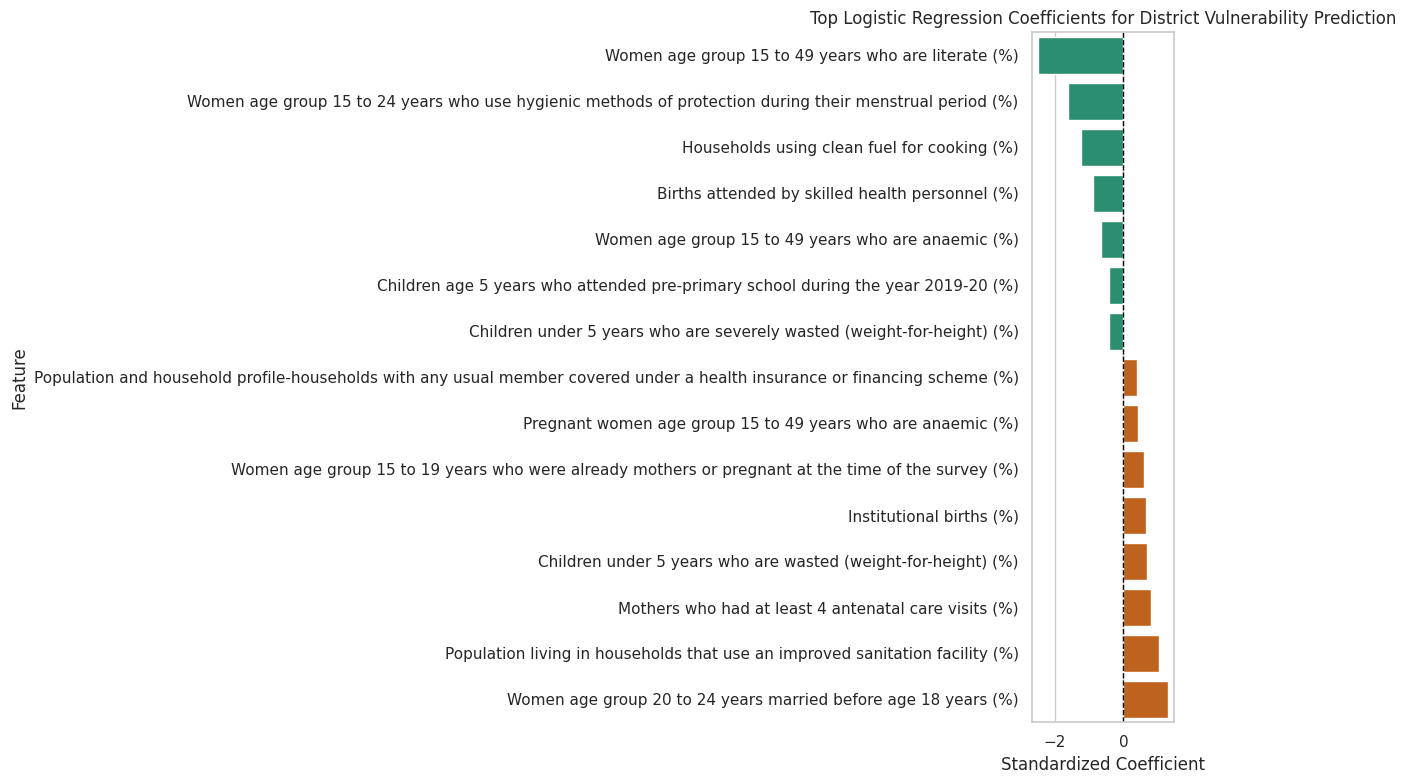

In [ ]:
# Plot top Logistic Regression coefficients

top_n = 15

plot_coef_df = coef_display.copy().sort_values("Coefficient")
top_negative = plot_coef_df.head(top_n // 2)
top_positive = plot_coef_df.tail(top_n - len(top_negative))

plot_df = pd.concat([top_negative, top_positive]).sort_values("Coefficient")

plt.figure(figsize=(12, 8))
colors = ["#d95f02" if x > 0 else "#1b9e77" for x in plot_df["Coefficient"]]

sns.barplot(
    data=plot_df,
    x="Coefficient",
    y="Feature",
    palette=colors
)

plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Top Logistic Regression Coefficients for District Vulnerability Prediction")
plt.xlabel("Standardized Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Threshold Sensitivity Analysis

The binary vulnerability label depends on a user-defined threshold applied to the district share of women with 10 or more years of schooling. Because this threshold is an operational choice, a sensitivity analysis is conducted to test whether the main modeling conclusions remain stable across nearby threshold values. This helps determine whether the observed model ranking and grouped-validation findings are robust or whether they depend heavily on a single cutoff.

In [ ]:
# Threshold sensitivity analysis for Logistic Regression under GroupKFold

thresholds = [25, 30, 35, 40, 45]

sensitivity_results = []

for threshold in thresholds:
    y_thresh = (df_model[target_col] < threshold).astype(int)

    class_counts = y_thresh.value_counts().to_dict()
    class_ratio = y_thresh.mean()  # proportion of vulnerable class

    lr_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])

    cv_results = cross_validate(
        lr_pipeline,
        X,
        y_thresh,
        cv=cv_grouped,
        groups=groups,
        scoring=scoring,
        n_jobs=-1
    )

    sensitivity_results.append({
        "Threshold": threshold,
        "Vulnerable Class Proportion": class_ratio,
        "Accuracy Mean": np.mean(cv_results["test_accuracy"]),
        "F1 Mean": np.mean(cv_results["test_f1"]),
        "ROC-AUC Mean": np.mean(cv_results["test_roc_auc"]),
        "PR-AUC Mean": np.mean(cv_results["test_pr_auc"]),
        "Accuracy Std": np.std(cv_results["test_accuracy"]),
        "F1 Std": np.std(cv_results["test_f1"]),
        "ROC-AUC Std": np.std(cv_results["test_roc_auc"]),
        "PR-AUC Std": np.std(cv_results["test_pr_auc"]),
        "Class Counts": class_counts
    })

sensitivity_df = pd.DataFrame(sensitivity_results)
display(sensitivity_df)

,Threshold,Vulnerable Class Proportion,Accuracy Mean,F1 Mean,ROC-AUC Mean,PR-AUC Mean,Accuracy Std,F1 Std,ROC-AUC Std,PR-AUC Std,Class Counts
0,25,0.1477,0.8637,0.5874,0.9232,0.6935,0.0333,0.0689,0.0244,0.1551,"{0: 600, 1: 104}"
1,30,0.2642,0.8367,0.7141,0.9308,0.8443,0.0158,0.0360,0.0190,0.0536,"{0: 518, 1: 186}"
2,35,0.3949,0.8409,0.8052,0.9433,0.9175,0.0356,0.0420,0.0148,0.0296,"{0: 426, 1: 278}"
3,40,0.5170,0.8608,0.8645,0.9442,0.9471,0.0393,0.0397,0.0271,0.0256,"{1: 364, 0: 340}"
4,45,0.6463,0.8651,0.8963,0.9464,0.9725,0.0555,0.0365,0.0332,0.0171,"{1: 455, 0: 249}"


## Interpreting Threshold Sensitivity

The sensitivity analysis shows that the main modeling conclusions remain broadly stable across multiple threshold values used to define district vulnerability. Logistic Regression continues to achieve strong performance under state-wise grouped cross-validation across all tested cutoffs. However, lower thresholds produce more severe class imbalance and lower PR-AUC, while higher thresholds alter the substantive meaning of vulnerability. The 35% threshold is therefore retained as the primary specification because it provides a reasonable balance between interpretability, policy relevance, and classification stability.

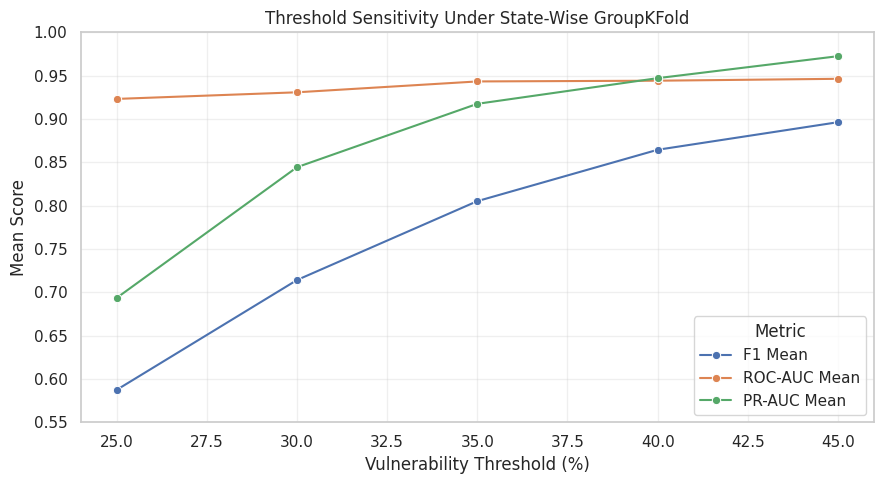

In [ ]:
# Multi-metric threshold sensitivity plot

plot_sensitivity = sensitivity_df.melt(
    id_vars=["Threshold"],
    value_vars=["F1 Mean", "ROC-AUC Mean", "PR-AUC Mean"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(9, 5))
sns.lineplot(
    data=plot_sensitivity,
    x="Threshold",
    y="Score",
    hue="Metric",
    marker="o"
)

plt.title("Threshold Sensitivity Under State-Wise GroupKFold")
plt.xlabel("Vulnerability Threshold (%)")
plt.ylabel("Mean Score")
plt.ylim(0.55, 1.0)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

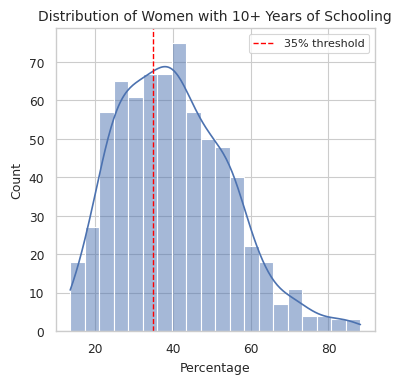

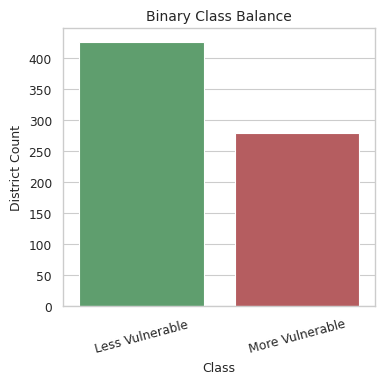

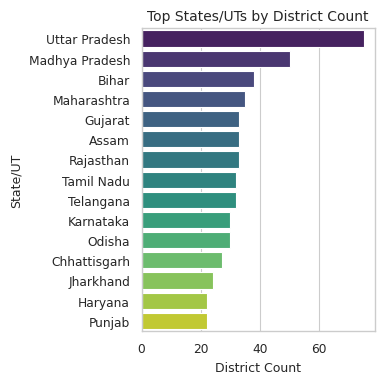

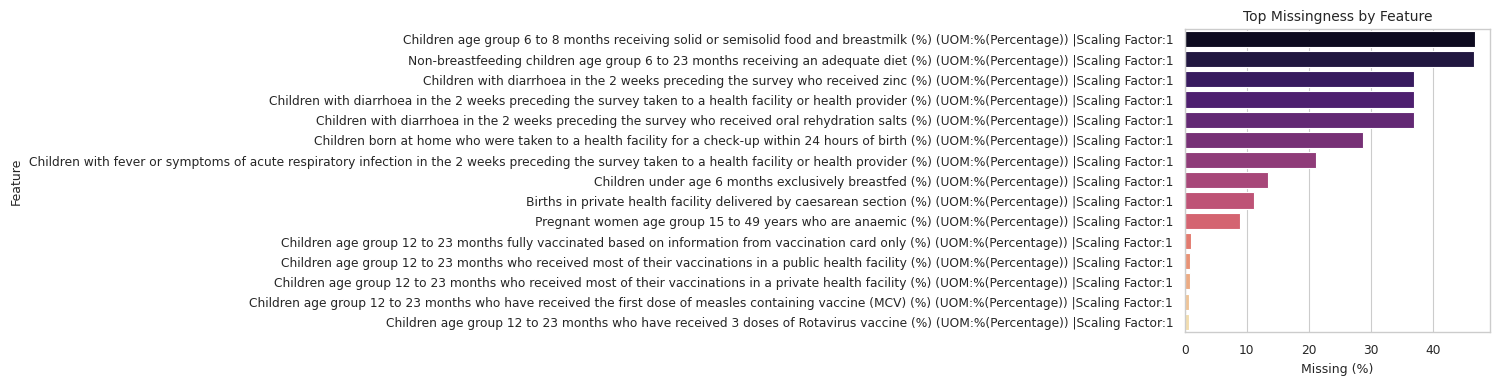

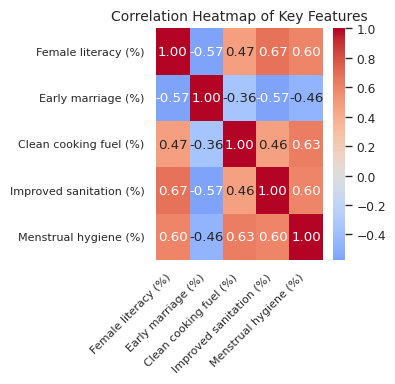

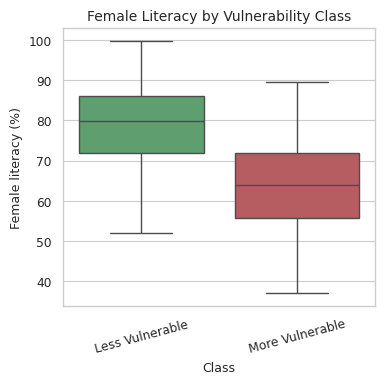

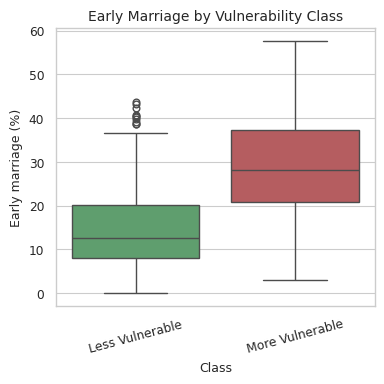

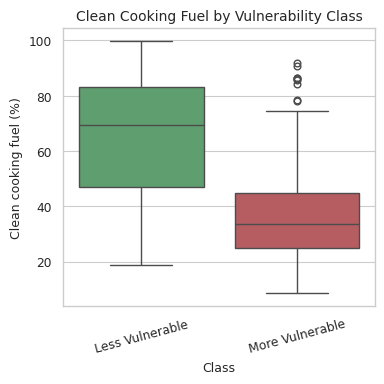

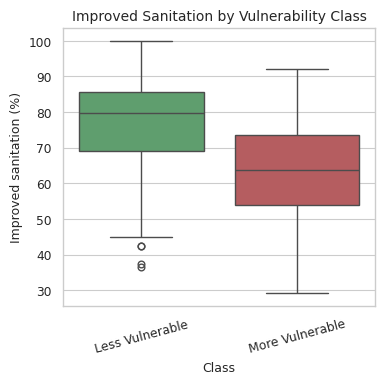

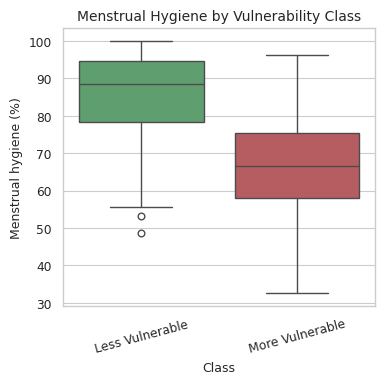

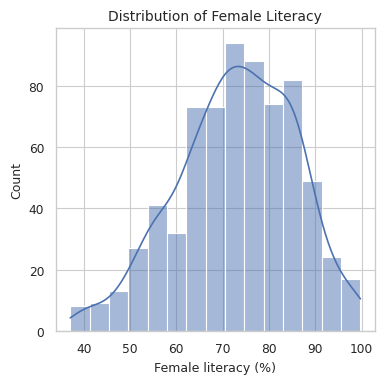

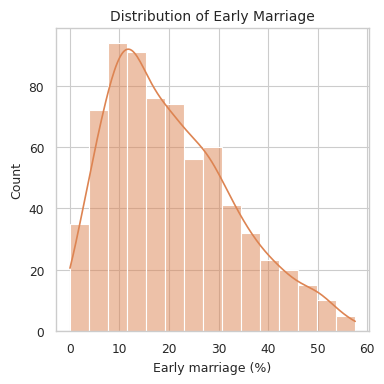

Dataset shape: (704, 110)
Modeling dataset shape: (704, 111)
Number of states/UTs: 34

Binary target distribution:


,Class,Count
0,Less Vulnerable,426
1,More Vulnerable,278


In [ ]:
# =========================
# EDA FIGURES
# One figure per row
# Each figure = 10 cm x 10 cm
# =========================

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
sns.set_context("paper")

CM_TO_INCH = 1 / 2.54
FIG_W = 10 * CM_TO_INCH
FIG_H = 10 * CM_TO_INCH

short_name_map = {
    "Women age group 15 to 49 years who are literate (%) (UOM:%(Percentage)) |Scaling Factor:1": "Female literacy (%)",
    "Women age group 20 to 24 years married before age 18 years (%) (UOM:%(Percentage)) |Scaling Factor:1": "Early marriage (%)",
    "Households using clean fuel for cooking (%) (UOM:%(Percentage)) |Scaling Factor:1": "Clean cooking fuel (%)",
    "Population living in households that use an improved sanitation facility (%) (UOM:%(Percentage)) |Scaling Factor:1": "Improved sanitation (%)",
    "Women age group 15 to 24 years who use hygienic methods of protection during their menstrual period (%) (UOM:%(Percentage)) |Scaling Factor:1": "Menstrual hygiene (%)",
    "Mothers who had at least 4 antenatal care visits (%) (UOM:%(Percentage)) |Scaling Factor:1": "4+ ANC visits (%)",
    "Institutional births (%) (UOM:%(Percentage)) |Scaling Factor:1": "Institutional births (%)",
    "Children under 5 years who are wasted (weight-for-height) (%) (UOM:%(Percentage)) |Scaling Factor:1": "Child wasting (%)"
}

eda_df = df_model.copy()
eda_df["Vulnerability Class"] = eda_df["vulnerable"].map({0: "Less Vulnerable", 1: "More Vulnerable"})

important_features = [
    "Women age group 15 to 49 years who are literate (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Women age group 20 to 24 years married before age 18 years (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Households using clean fuel for cooking (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Population living in households that use an improved sanitation facility (%) (UOM:%(Percentage)) |Scaling Factor:1",
    "Women age group 15 to 24 years who use hygienic methods of protection during their menstrual period (%) (UOM:%(Percentage)) |Scaling Factor:1"
]

# -------------------------
# Figure 1: Target distribution
# -------------------------
plt.figure(figsize=(FIG_W, FIG_H))
sns.histplot(eda_df[target_col], bins=20, kde=True, color="#4C72B0")
plt.axvline(35, color="red", linestyle="--", linewidth=1, label="35% threshold")
plt.title("Distribution of Women with 10+ Years of Schooling", fontsize=10)
plt.xlabel("Percentage", fontsize=9)
plt.ylabel("Count", fontsize=9)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 2: Binary class balance
# -------------------------
plt.figure(figsize=(FIG_W, FIG_H))
class_counts = eda_df["Vulnerability Class"].value_counts()
sns.barplot(x=class_counts.index, y=class_counts.values, palette=["#55A868", "#C44E52"])
plt.title("Binary Class Balance", fontsize=10)
plt.xlabel("Class", fontsize=9)
plt.ylabel("District Count", fontsize=9)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 3: District count by state
# -------------------------
plt.figure(figsize=(FIG_W, FIG_H))
state_counts = eda_df[group_col].value_counts().sort_values(ascending=False)
top_states = state_counts.head(15)
sns.barplot(x=top_states.values, y=top_states.index, palette="viridis")
plt.title("Top States/UTs by District Count", fontsize=10)
plt.xlabel("District Count", fontsize=9)
plt.ylabel("State/UT", fontsize=9)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 4: Missingness
# -------------------------
missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
missing_pct_nonzero = missing_pct[missing_pct > 0].head(15)

plt.figure(figsize=(FIG_W, FIG_H))
if len(missing_pct_nonzero) > 0:
    sns.barplot(x=missing_pct_nonzero.values, y=missing_pct_nonzero.index, palette="magma")
    plt.title("Top Missingness by Feature", fontsize=10)
    plt.xlabel("Missing (%)", fontsize=9)
    plt.ylabel("Feature", fontsize=9)
else:
    plt.text(0.5, 0.5, "No missing values", ha="center", va="center", fontsize=12)
    plt.title("Top Missingness by Feature", fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()

# -------------------------
# Figure 5: Correlation heatmap
# -------------------------
corr_features = [col for col in important_features if col in eda_df.columns]
corr_matrix = eda_df[corr_features].corr()

plt.figure(figsize=(FIG_W, FIG_H))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    xticklabels=[short_name_map.get(c, c) for c in corr_matrix.columns],
    yticklabels=[short_name_map.get(c, c) for c in corr_matrix.index]
)
plt.title("Correlation Heatmap of Key Features", fontsize=10)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 6: Female literacy by class
# -------------------------
col = "Women age group 15 to 49 years who are literate (%) (UOM:%(Percentage)) |Scaling Factor:1"
plt.figure(figsize=(FIG_W, FIG_H))
sns.boxplot(data=eda_df, x="Vulnerability Class", y=col, palette=["#55A868", "#C44E52"])
plt.title("Female Literacy by Vulnerability Class", fontsize=10)
plt.xlabel("Class", fontsize=9)
plt.ylabel("Female literacy (%)", fontsize=9)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 7: Early marriage by class
# -------------------------
col = "Women age group 20 to 24 years married before age 18 years (%) (UOM:%(Percentage)) |Scaling Factor:1"
plt.figure(figsize=(FIG_W, FIG_H))
sns.boxplot(data=eda_df, x="Vulnerability Class", y=col, palette=["#55A868", "#C44E52"])
plt.title("Early Marriage by Vulnerability Class", fontsize=10)
plt.xlabel("Class", fontsize=9)
plt.ylabel("Early marriage (%)", fontsize=9)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 8: Clean fuel by class
# -------------------------
col = "Households using clean fuel for cooking (%) (UOM:%(Percentage)) |Scaling Factor:1"
plt.figure(figsize=(FIG_W, FIG_H))
sns.boxplot(data=eda_df, x="Vulnerability Class", y=col, palette=["#55A868", "#C44E52"])
plt.title("Clean Cooking Fuel by Vulnerability Class", fontsize=10)
plt.xlabel("Class", fontsize=9)
plt.ylabel("Clean cooking fuel (%)", fontsize=9)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 9: Sanitation by class
# -------------------------
col = "Population living in households that use an improved sanitation facility (%) (UOM:%(Percentage)) |Scaling Factor:1"
plt.figure(figsize=(FIG_W, FIG_H))
sns.boxplot(data=eda_df, x="Vulnerability Class", y=col, palette=["#55A868", "#C44E52"])
plt.title("Improved Sanitation by Vulnerability Class", fontsize=10)
plt.xlabel("Class", fontsize=9)
plt.ylabel("Improved sanitation (%)", fontsize=9)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 10: Menstrual hygiene by class
# -------------------------
col = "Women age group 15 to 24 years who use hygienic methods of protection during their menstrual period (%) (UOM:%(Percentage)) |Scaling Factor:1"
plt.figure(figsize=(FIG_W, FIG_H))
sns.boxplot(data=eda_df, x="Vulnerability Class", y=col, palette=["#55A868", "#C44E52"])
plt.title("Menstrual Hygiene by Vulnerability Class", fontsize=10)
plt.xlabel("Class", fontsize=9)
plt.ylabel("Menstrual hygiene (%)", fontsize=9)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 11: Distribution of female literacy
# -------------------------
col = "Women age group 15 to 49 years who are literate (%) (UOM:%(Percentage)) |Scaling Factor:1"
plt.figure(figsize=(FIG_W, FIG_H))
sns.histplot(eda_df[col], bins=15, kde=True, color="#4C72B0")
plt.title("Distribution of Female Literacy", fontsize=10)
plt.xlabel("Female literacy (%)", fontsize=9)
plt.ylabel("Count", fontsize=9)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 12: Distribution of early marriage
# -------------------------
col = "Women age group 20 to 24 years married before age 18 years (%) (UOM:%(Percentage)) |Scaling Factor:1"
plt.figure(figsize=(FIG_W, FIG_H))
sns.histplot(eda_df[col], bins=15, kde=True, color="#DD8452")
plt.title("Distribution of Early Marriage", fontsize=10)
plt.xlabel("Early marriage (%)", fontsize=9)
plt.ylabel("Count", fontsize=9)
plt.tight_layout()
plt.show()

print("Dataset shape:", df.shape)
print("Modeling dataset shape:", df_model.shape)
print("Number of states/UTs:", eda_df[group_col].nunique())
print("\nBinary target distribution:")
display(eda_df["Vulnerability Class"].value_counts().rename_axis("Class").reset_index(name="Count"))

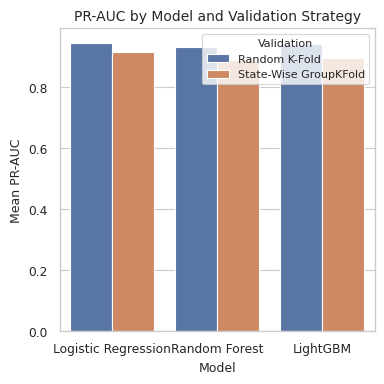

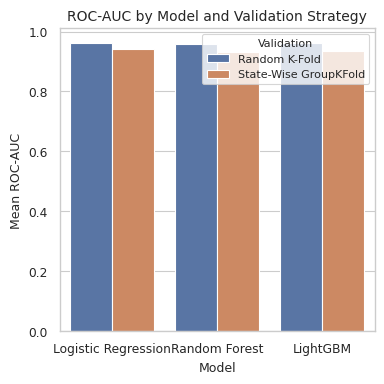

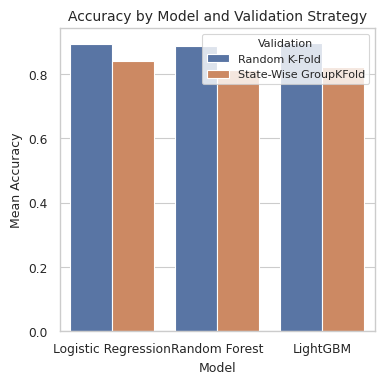

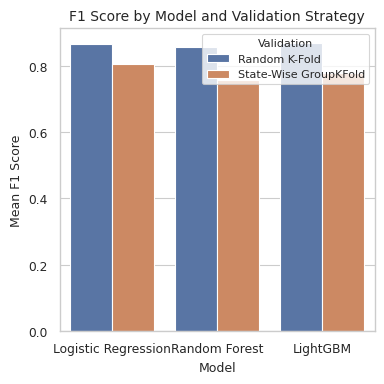

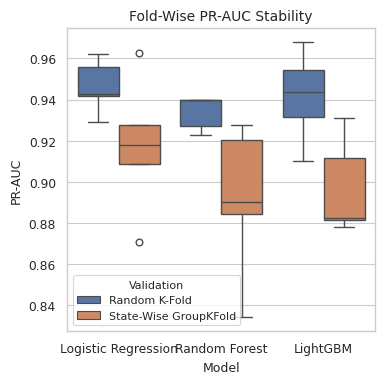

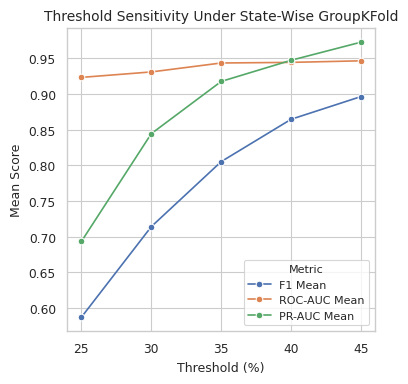

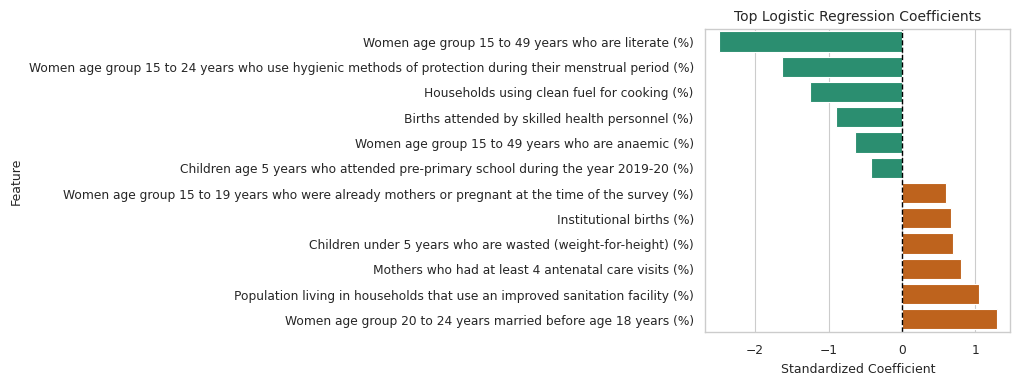

Baseline results:


,Model,Validation,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std,PR-AUC Mean,PR-AUC Std
0,DummyClassifier,Random K-Fold,0.6051,0.0441,0.0000,0.0000,0.5000,0.0000,0.3949,0.0441
1,DummyClassifier,State-Wise GroupKFold,0.6051,0.0422,0.0000,0.0000,0.5000,0.0000,0.3949,0.0422


Main model comparison:


,Model,Validation,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std,PR-AUC Mean,PR-AUC Std
0,Logistic Regression,Random K-Fold,0.8935,0.0161,0.8666,0.0259,0.9621,0.0070,0.9463,0.0116
4,LightGBM,Random K-Fold,0.8977,0.0095,0.8701,0.0103,0.9622,0.0108,0.9415,0.0197
2,Random Forest,Random K-Fold,0.8878,0.0136,0.8577,0.0178,0.9569,0.0028,0.9339,0.0074
1,Logistic Regression,State-Wise GroupKFold,0.8409,0.0356,0.8052,0.0420,0.9433,0.0148,0.9175,0.0296
5,LightGBM,State-Wise GroupKFold,0.8239,0.0315,0.7800,0.0406,0.9343,0.0055,0.8969,0.0209
3,Random Forest,State-Wise GroupKFold,0.8125,0.0508,0.7592,0.0714,0.9318,0.0143,0.8912,0.0330


Threshold sensitivity:


,Threshold,Vulnerable Class Proportion,Accuracy Mean,F1 Mean,ROC-AUC Mean,PR-AUC Mean,Accuracy Std,F1 Std,ROC-AUC Std,PR-AUC Std,Class Counts
0,25,0.1477,0.8637,0.5874,0.9232,0.6935,0.0333,0.0689,0.0244,0.1551,"{0: 600, 1: 104}"
1,30,0.2642,0.8367,0.7141,0.9308,0.8443,0.0158,0.0360,0.0190,0.0536,"{0: 518, 1: 186}"
2,35,0.3949,0.8409,0.8052,0.9433,0.9175,0.0356,0.0420,0.0148,0.0296,"{0: 426, 1: 278}"
3,40,0.5170,0.8608,0.8645,0.9442,0.9471,0.0393,0.0397,0.0271,0.0256,"{1: 364, 0: 340}"
4,45,0.6463,0.8651,0.8963,0.9464,0.9725,0.0555,0.0365,0.0332,0.0171,"{1: 455, 0: 249}"


In [ ]:
# =========================
# RESULTS / METRICS FIGURES
# One figure per row
# Each figure = 10 cm x 10 cm
# =========================

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
sns.set_context("paper")

CM_TO_INCH = 1 / 2.54
FIG_W = 10 * CM_TO_INCH
FIG_H = 10 * CM_TO_INCH

results_plot_df = results_df.copy()
fold_plot_df = fold_results_df.copy()
sens_plot_df = sensitivity_df.copy()
coef_plot_df = coef_display.copy()

# -------------------------
# Figure 1: PR-AUC comparison
# -------------------------
plt.figure(figsize=(FIG_W, FIG_H))
sns.barplot(
    data=results_plot_df,
    x="Model",
    y="PR-AUC Mean",
    hue="Validation"
)
plt.title("PR-AUC by Model and Validation Strategy", fontsize=10)
plt.xlabel("Model", fontsize=9)
plt.ylabel("Mean PR-AUC", fontsize=9)
plt.legend(title="Validation", fontsize=8, title_fontsize=8)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 2: ROC-AUC comparison
# -------------------------
plt.figure(figsize=(FIG_W, FIG_H))
sns.barplot(
    data=results_plot_df,
    x="Model",
    y="ROC-AUC Mean",
    hue="Validation"
)
plt.title("ROC-AUC by Model and Validation Strategy", fontsize=10)
plt.xlabel("Model", fontsize=9)
plt.ylabel("Mean ROC-AUC", fontsize=9)
plt.legend(title="Validation", fontsize=8, title_fontsize=8)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 3: Accuracy comparison
# -------------------------
plt.figure(figsize=(FIG_W, FIG_H))
sns.barplot(
    data=results_plot_df,
    x="Model",
    y="Accuracy Mean",
    hue="Validation"
)
plt.title("Accuracy by Model and Validation Strategy", fontsize=10)
plt.xlabel("Model", fontsize=9)
plt.ylabel("Mean Accuracy", fontsize=9)
plt.legend(title="Validation", fontsize=8, title_fontsize=8)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 4: F1 comparison
# -------------------------
plt.figure(figsize=(FIG_W, FIG_H))
sns.barplot(
    data=results_plot_df,
    x="Model",
    y="F1 Mean",
    hue="Validation"
)
plt.title("F1 Score by Model and Validation Strategy", fontsize=10)
plt.xlabel("Model", fontsize=9)
plt.ylabel("Mean F1 Score", fontsize=9)
plt.legend(title="Validation", fontsize=8, title_fontsize=8)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 5: Fold-wise PR-AUC stability
# -------------------------
plt.figure(figsize=(FIG_W, FIG_H))
sns.boxplot(
    data=fold_plot_df,
    x="Model",
    y="PR-AUC",
    hue="Validation"
)
plt.title("Fold-Wise PR-AUC Stability", fontsize=10)
plt.xlabel("Model", fontsize=9)
plt.ylabel("PR-AUC", fontsize=9)
plt.legend(title="Validation", fontsize=8, title_fontsize=8)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 6: Threshold sensitivity
# -------------------------
sens_long = sens_plot_df.melt(
    id_vars=["Threshold"],
    value_vars=["F1 Mean", "ROC-AUC Mean", "PR-AUC Mean"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(FIG_W, FIG_H))
sns.lineplot(
    data=sens_long,
    x="Threshold",
    y="Score",
    hue="Metric",
    marker="o"
)
plt.title("Threshold Sensitivity Under State-Wise GroupKFold", fontsize=10)
plt.xlabel("Threshold (%)", fontsize=9)
plt.ylabel("Mean Score", fontsize=9)
plt.legend(title="Metric", fontsize=8, title_fontsize=8)
plt.tight_layout()
plt.show()

# -------------------------
# Figure 7: Logistic Regression coefficients
# -------------------------
top_n = 12
coef_temp = coef_plot_df.copy().sort_values("Coefficient")
top_negative = coef_temp.head(top_n // 2)
top_positive = coef_temp.tail(top_n - len(top_negative))
coef_final = pd.concat([top_negative, top_positive]).sort_values("Coefficient")

colors = ["#1b9e77" if x < 0 else "#d95f02" for x in coef_final["Coefficient"]]

plt.figure(figsize=(FIG_W, FIG_H))
sns.barplot(
    data=coef_final,
    x="Coefficient",
    y="Feature",
    palette=colors
)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Top Logistic Regression Coefficients", fontsize=10)
plt.xlabel("Standardized Coefficient", fontsize=9)
plt.ylabel("Feature", fontsize=9)
plt.tight_layout()
plt.show()

print("Baseline results:")
display(dummy_results)

print("Main model comparison:")
display(results_df.sort_values(["Validation", "PR-AUC Mean"], ascending=[True, False]))

print("Threshold sensitivity:")
display(sensitivity_df)

In [ ]:
# Paste at the END of your notebook (uses X, y, groups, models, scoring,
# preprocessor, cv_random, cv_grouped, df_model, feature_cols, RANDOM_STATE).
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (KFold, GroupKFold, StratifiedGroupKFold,
                                     cross_validate)

models["LightGBM"].set_params(verbose=-1)          # silence warnings
METRICS = ["accuracy", "f1", "roc_auc", "pr_auc"]

def pipe(model, cols=None):
    cols = cols if cols is not None else list(X.columns)
    pre = ColumnTransformer([("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler())]), cols)])
    return Pipeline([("pre", pre), ("clf", model)])

def run(p, Xd, cv, grp=None):
    r = cross_validate(p, Xd, y, cv=cv, groups=grp, scoring=scoring, n_jobs=-1)
    return {m: r[f"test_{m}"] for m in METRICS}

def summ(v):
    v = np.asarray(v); n = len(v); sd = v.std(ddof=1)
    h = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
    return v.mean(), sd, v.mean() - h, v.mean() + h

# ---------- 1. Per-fold results for the ORIGINAL 5-fold setups ----------
rows, fold_scores = [], {}
for name, m in models.items():
    for vname, cv, g in [("Random", cv_random, None), ("Grouped", cv_grouped, groups)]:
        res = run(pipe(m), X, cv, g)
        fold_scores[(name, vname)] = res
        for k in METRICS:
            mean, sd, lo, hi = summ(res[k])
            rows.append(dict(Model=name, Validation=vname, Metric=k,
                             Mean=mean, SD=sd, CI_low=lo, CI_high=hi,
                             Folds=np.round(res[k], 4).tolist()))
per_fold = pd.DataFrame(rows)
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", None)
print("=== Per-fold summary (SD uses ddof=1; CI is t-based, df=4) ===")
display(per_fold)

# ---------- 2. States in each GroupKFold test fold ----------
print("=== States per grouped test fold ===")
for i, (_, te) in enumerate(cv_grouped.split(X, y, groups), 1):
    st = sorted(groups.iloc[te].unique())
    print(f"Fold {i} (n={len(te)}, vulnerable={int(y.iloc[te].sum())}): {', '.join(st)}")

# ---------- 3. Paired model comparison on identical grouped folds ----------
print("=== Paired differences, grouped folds (LR minus other) ===")
for other in ["Random Forest", "LightGBM"]:
    for k in ["pr_auc", "roc_auc", "f1"]:
        d = fold_scores[("Logistic Regression", "Grouped")][k] - fold_scores[(other, "Grouped")][k]
        mean, sd, lo, hi = summ(d)
        t, p = stats.ttest_1samp(d, 0)
        print(f"LR-{other:14s} {k:7s} diff={mean:+.4f}  95%CI[{lo:+.4f},{hi:+.4f}]  p={p:.3f}")

# ---------- 4. Repeated CV (10 repeats) so results don't hinge on one split ----------
R = 10
rep_rows = []
for name, m in models.items():
    for r in range(R):
        kf = KFold(5, shuffle=True, random_state=r)
        sg = StratifiedGroupKFold(5, shuffle=True, random_state=r)  # shuffled, class-stratified state folds
        for vname, cv, g in [("Random", kf, None), ("Grouped", sg, groups)]:
            res = run(pipe(m), X, cv, g)
            for k in METRICS:
                rep_rows.append(dict(Model=name, Validation=vname, Repeat=r, Metric=k,
                                     RepeatMean=np.mean(res[k]), FoldSD=np.std(res[k], ddof=1)))
rep = pd.DataFrame(rep_rows)
rep_summary = (rep.groupby(["Model", "Validation", "Metric"])
                  .agg(Mean=("RepeatMean", "mean"),
                       SD_across_repeats=("RepeatMean", "std"),
                       Typical_fold_SD=("FoldSD", "mean")).round(4))
print("=== Repeated CV (10 x 5-fold) ===")
display(rep_summary)

# ---------- 5. Predictor-selection robustness (LR, grouped CV) ----------
def lr(): return LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
def grouped_pr(cols, Xd):
    return run(pipe(lr(), cols), Xd, cv_grouped, groups)

curated = list(X.columns)
pool = df_model[feature_cols]
miss = pool.isna().mean()
pool_ok = pool.loc[:, miss <= 0.40]                       # drop >40% missing
print(f"Candidate pool: {pool.shape[1]} columns, {pool_ok.shape[1]} with <=40% missing")

out = []
r = grouped_pr(list(pool_ok.columns), pool_ok)
out.append(("All candidates (<=40% missing), LR", np.mean(r["pr_auc"]), np.mean(r["roc_auc"])))
r = grouped_pr(curated, X)
out.append(("Curated 25, LR", np.mean(r["pr_auc"]), np.mean(r["roc_auc"])))
proxy = [c for c in curated if ("are literate" in c) or ("ever attended school" in c)]
keep = [c for c in curated if c not in proxy]
r = grouped_pr(keep, X[keep])
out.append((f"Curated 25 minus {len(proxy)} education-proxy vars, LR", np.mean(r["pr_auc"]), np.mean(r["roc_auc"])))

rng = np.random.default_rng(RANDOM_STATE)
rand_pr = []
for _ in range(200):
    cols = list(rng.choice(pool_ok.columns, 25, replace=False))
    rand_pr.append(np.mean(grouped_pr(cols, pool_ok[cols])["pr_auc"]))
rand_pr = np.array(rand_pr)
out.append(("Random 25 from pool (mean of 200 draws), LR", rand_pr.mean(), np.nan))
print(pd.DataFrame(out, columns=["Feature set", "Grouped PR-AUC", "Grouped ROC-AUC"]).round(4).to_string(index=False))
print(f"Random-25 PR-AUC: 5th-95th pct = {np.percentile(rand_pr,5):.4f}-{np.percentile(rand_pr,95):.4f}; "
      f"curated set percentile = {(rand_pr < np.mean(fold_scores[('Logistic Regression','Grouped')]['pr_auc'])).mean()*100:.0f}")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

=== Per-fold summary (SD uses ddof=1; CI is t-based, df=4) ===


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Validation,Metric,Mean,SD,CI_low,CI_high,Folds
0,Logistic Regression,Random,accuracy,0.8935,0.0180,0.8711,0.9158,"[0.8794, 0.922, 0.8794, 0.8865, 0.9]"
1,Logistic Regression,Random,f1,0.8666,0.0289,0.8307,0.9025,"[0.8702, 0.906, 0.844, 0.8333, 0.8793]"
2,Logistic Regression,Random,roc_auc,0.9621,0.0079,0.9524,0.9719,"[0.9518, 0.9647, 0.956, 0.9694, 0.9687]"
3,Logistic Regression,Random,pr_auc,0.9463,0.0129,0.9302,0.9624,"[0.9427, 0.956, 0.9291, 0.9418, 0.9619]"
4,Logistic Regression,Grouped,accuracy,0.8409,0.0399,0.7915,0.8904,"[0.8014, 0.7943, 0.8794, 0.8652, 0.8643]"
5,Logistic Regression,Grouped,f1,0.8052,0.0469,0.7469,0.8634,"[0.7667, 0.7642, 0.8794, 0.8155, 0.8]"
6,Logistic Regression,Grouped,roc_auc,0.9433,0.0166,0.9227,0.9639,"[0.9375, 0.9185, 0.9631, 0.9487, 0.9488]"
7,Logistic Regression,Grouped,pr_auc,0.9175,0.0331,0.8763,0.9586,"[0.9178, 0.8708, 0.9625, 0.9086, 0.9278]"
8,Random Forest,Random,accuracy,0.8878,0.0152,0.8690,0.9066,"[0.8723, 0.8794, 0.8794, 0.9007, 0.9071]"
9,Random Forest,Random,f1,0.8577,0.0199,0.8329,0.8824,"[0.8615, 0.8571, 0.8317, 0.8511, 0.887]"


=== States per grouped test fold ===
Fold 1 (n=141, vulnerable=51): Jammu And Kashmir, Jharkhand, Ladakh, Manipur, Meghalaya, Uttar Pradesh
Fold 2 (n=141, vulnerable=51): Andhra Pradesh, Goa, Haryana, Kerala, Madhya Pradesh, Puducherry, Sikkim, Telangana
Fold 3 (n=141, vulnerable=67): Bihar, Chhattisgarh, Tamil Nadu, The Dadra And Nagar Haveli And Daman And Diu, Tripura, Uttarakhand, West Bengal
Fold 4 (n=141, vulnerable=56): Andaman And Nicobar Islands, Arunachal Pradesh, Himachal Pradesh, Maharashtra, Mizoram, Odisha, Rajasthan
Fold 5 (n=140, vulnerable=53): Assam, Delhi, Gujarat, Karnataka, Nagaland, Punjab
=== Paired differences, grouped folds (LR minus other) ===
LR-Random Forest  pr_auc  diff=+0.0263  95%CI[-0.0382,+0.0908]  p=0.321
LR-Random Forest  roc_auc diff=+0.0116  95%CI[-0.0182,+0.0413]  p=0.341
LR-Random Forest  f1      diff=+0.0459  95%CI[-0.0441,+0.1360]  p=0.230
LR-LightGBM       pr_auc  diff=+0.0206  95%CI[-0.0118,+0.0530]  p=0.152
LR-LightGBM       roc_auc diff=+0.0

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

=== Repeated CV (10 x 5-fold) ===


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Mean  SD_across_repeats  Typical_fold_SD
Model               Validation Metric                                             
LightGBM            Grouped    accuracy 0.8298             0.0100           0.0426
                               f1       0.7706             0.0220           0.0599
                               pr_auc   0.8834             0.0102           0.0581
                               roc_auc  0.9277             0.0047           0.0279
                    Random     accuracy 0.8862             0.0071           0.0297
                               f1       0.8558             0.0091           0.0391
                               pr_auc   0.9404             0.0053           0.0259
                               roc_auc  0.9591             0.0033           0.0160
Logistic Regression Grouped    accuracy 0.8561             0.0166           0.0437
                               f1       0.8106             0.0199           0.0625
                               pr_auc   0.9280             0.0105           0.0435
                               roc_auc  0.9530             0.0059           0.0226
                    Random     accuracy 0.8935             0.0056           0.0253
                               f1       0.8689             0.0062           0.0305
                               pr_auc   0.9495             0.0023           0.0194
                               roc_auc  0.9643             0.0014           0.0143
Random Forest       Grouped    accuracy 0.8252             0.0086           0.0519
                               f1       0.7644             0.0158           0.0588
                               pr_auc   0.8895             0.0127           0.0528
                               roc_auc  0.9309             0.0085           0.0326
                    Random     accuracy 0.8810             0.0048           0.0296
                               f1       0.8485             0.0070           0.0387
                               pr_auc   0.9297             0.0047           0.0326
                               roc_auc  0.9555             0.0025           0.0169

Candidate pool: 103 columns, 101 with <=40% missing
                                Feature set  Grouped PR-AUC  Grouped ROC-AUC
         All candidates (<=40% missing), LR          0.9228           0.9428
                             Curated 25, LR          0.9175           0.9433
Curated 25 minus 2 education-proxy vars, LR          0.9001           0.9311
Random 25 from pool (mean of 200 draws), LR          0.8594              NaN
Random-25 PR-AUC: 5th-95th pct = 0.7845-0.9237; curated set percentile = 92
